# Jogo da Velha - Humano vs Máquina
## Busca competitiva (Minimax)

O tabuleiro é uma matriz 3x3 (mesma ideia do ambiente do aspirador):

- `0` = vazio (azul)
- `1` = X, o humano (verde)
- `2` = O, a máquina (amarelo)

A máquina usa Minimax: ela assume que o humano sempre joga o melhor possível e escolhe a jogada que maximiza o resultado no pior caso. Nesta versão a árvore é explorada inteira, sem poda.

### Preparação do projeto

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import clear_output
import math
import random

VAZIO, HUMANO, MAQUINA = 0, 1, 2
SIMBOLO = {HUMANO: 'X', MAQUINA: 'O'}

# Cores do tabuleiro: 0 = azul, 1 = verde, 2 = amarelo
cores = ListedColormap(['blue', 'green', 'yellow'])

### Criando e exibindo o tabuleiro

In [2]:
# cria o estado inicial: matriz 3x3 toda com 0 (vazia)
def criar_tabuleiro():
    return np.zeros((3, 3), dtype=int)

#   tab -> matriz 3x3 com o estado atual do jogo
#   titulo -> texto que aparece em cima do desenho
def exibir(tab, titulo="Jogo da Velha"):
    # apaga o desenho anterior pra o notebook não encher de imagens
    clear_output()
    plt.figure(figsize=(5, 5))
    
    # pinta cada casa com a cor do seu valor (0 azul, 1 verde, 2 amarelo)
    plt.imshow(tab, cmap=cores, vmin=0, vmax=2)
    plt.title(titulo)

     # escreve o conteúdo de cada casa
    for i in range(3):
        for j in range(3):
            if tab[i][j] != VAZIO:
                # casa ocupada: escreve X ou O grande
                plt.text(j, i, SIMBOLO[tab[i][j]], ha='center', va='center',
                         fontsize=40, fontweight='bold', color='black')
            else:
                # número da posição (1 a 9), pra ajudar o humano a jogar
                plt.text(j, i, str(i * 3 + j + 1), ha='center', va='center',
                         fontsize=14, color='white')

    # Remove os números dos ixos, que nçao servem para nada
    plt.xticks([])
    plt.yticks([])

     # desenha as linhas brancas que separam as casas
    eixo = plt.gca()
    eixo.set_xticks(np.arange(-0.5, 3, 1), minor=True)
    eixo.set_yticks(np.arange(-0.5, 3, 1), minor=True)
    eixo.grid(which='minor', color='white', linewidth=4)

    # legenda embaixo do tabuleiro
    legenda = [Patch(color='blue',   label='Vazio'),
               Patch(color='green',  label='Humano (X)'),
               Patch(color='yellow', label='Máquina (O)')]
    plt.legend(handles=legenda, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
    plt.show()

### Regras do jogo

- `jogadas_possiveis`: casas vazias (as ações do jogo)
- `vencedor`: quem completou uma linha, coluna ou diagonal (ou `VAZIO` se ninguém)
- teste de término: alguém venceu ou o tabuleiro está cheio (empate)

In [3]:
# Lista com posição de cada casa vaiza
def jogadas_possiveis(tab):
    return [(i, j) for i in range(3) for j in range(3) if tab[i][j] == VAZIO]

# verifica vencedor 
# retorna Humano (1), Maquina (2), ou Vazio (0) se ningue ganhou ainda
def vencedor(tab):
    # monta as 8 sequências
    linhas = [tab[i, :] for i in range(3)]          # 3 linhas
    linhas += [tab[:, j] for j in range(3)]         # 3 colunas
    linhas += [np.diag(tab), np.diag(np.fliplr(tab))]  # 2 diagonais
    
    # se as 3 casas de uma sequência forem iguais e não vaizas, este jogador vence
    for l in linhas:
        if l[0] != VAZIO and l[0] == l[1] == l[2]:
            return l[0]
    return VAZIO

# O jogo acaba se algué ganho ou se não sobrou casa vazia (empate)
def fim_de_jogo(tab):
    return vencedor(tab) != VAZIO or len(jogadas_possiveis(tab)) == 0

### Minimax

**Utilidade** (vista pela máquina):
- vitória da máquina = `+1`
- vitória do humano = `-1`
- empate = `0`

Subtrair a profundidade faz a máquina preferir vencer **mais rápido** e perder **mais devagar**.

- A máquina é **MAX** (quer o maior valor); o humano é **MIN** (quer o menor).
- Como não há poda, todos os nós da árvore são visitados (no tabuleiro vazio são quase 550 mil), por isso a primeira jogada da máquina pode levar alguns segundos.
- Limitação: como toda vitória vale +1, a máquina não diferencia ganhar agora de ganhar algumas jogadas depois. Ela nunca perde, mas às vezes demora a fechar a vitória.

In [4]:
nos_visitados = 0   # conta quantos estados a busca examinou


# calcula o valor de um estado do jogo
#   tab -> tabuleiro atual
#   jogador -> de quem é a vez (MAQUINA = MAX, HUMANO = MIN)
# retorna +1 (máquina ganha), -1 (humano ganha) ou 0 (empate),
# considerando que os dois jogam da melhor forma possível daqui pra frente

def minimax(tab, jogador):
    global nos_visitados #cria variável global de quantos nós foram visitados
    nos_visitados += 1

    # casos base (estados terminais): aplica a função de utilidade
    v = vencedor(tab)
    if v == MAQUINA:
        return 1 # máquina vence
    if v == HUMANO:
        return -1 #humano vence
    if len(jogadas_possiveis(tab)) == 0:
        return 0   # empate

    if jogador == MAQUINA:          # nó MAX: escolhe o maior valor
        melhor = -math.inf          # começa com -infinito, qualquer valor real é maior
        for (i, j) in jogadas_possiveis(tab):
            tab[i][j] = MAQUINA     # simula a jogada da máquina
            valor = minimax(tab, HUMANO) # vez do humano
            tab[i][j] = VAZIO       # desfaz a jogada
            melhor = max(melhor, valor)
        return melhor
    else:                           # nó MIN: escolhe o menor valor
        melhor = math.inf           # começa com +infinito, qualquer valor real é menor
        for (i, j) in jogadas_possiveis(tab):
            tab[i][j] = HUMANO      # simula a jogada do humano
            valor = minimax(tab, MAQUINA) #vez da máquina
            tab[i][j] = VAZIO       # desfaz a jogada
            melhor = min(melhor, valor)
        return melhor


# decide onde a máquina vai jogar
# testa cada casa vazia, calcula o valor minimax e fica com a de maior valor
# retorna a posição (linha, coluna) escolhida
def melhor_jogada(tab):
    # testa cada jogada possível da máquina e fica com a de maior valor minimax
    global nos_visitados
    nos_visitados = 0
    melhor_valor = -math.inf
    melhor = None
    for (i, j) in jogadas_possiveis(tab):
        tab[i][j] = MAQUINA
        valor = minimax(tab, HUMANO)  # depois da jogada da máquina, a vez é do humano
        tab[i][j] = VAZIO
        # usa ">" e não ">=": em caso de empate de valores, fica com a primeira casa encontrada
        if valor > melhor_valor:
            melhor_valor = valor
            melhor = (i, j)
    return melhor

### Jogada do humano

O humano digita o número da casa (1 a 9, como aparece no tabuleiro) ou `q` para sair.

In [5]:
# pede pro humano digitar a jogada e só aceita uma entrada válida
# retorna a posição (linha, coluna) escolhida, ou None se ele digitar q pra sair
def pedir_jogada_humano(tab):
    while True:   # repete até receber uma jogada válida
        entrada = input("Sua jogada (1-9, ou q para sair): ").strip().lower()
        if entrada == 'q':
            return None

        # tem que ser um número de 1 a 9
        if not entrada.isdigit() or not (1 <= int(entrada) <= 9):
            print("Digite um número de 1 a 9.")
            continue

        # converte o número da casa (1 a 9) em linha e coluna (0 a 2)
        #   ex.: casa 6 -> pos 5 -> linha 5 // 3 = 1, coluna 5 % 3 = 2
        pos = int(entrada) - 1
        i, j = pos // 3, pos % 3

        # não deixa jogar em casa ocupada
        if tab[i][j] != VAZIO:
            print("Essa casa já está ocupada.")
            continue
        return (i, j)

### Jogando

`jogar(humano_comeca=True)` roda uma partida completa. Mude para `False` se quiser que a máquina comece.

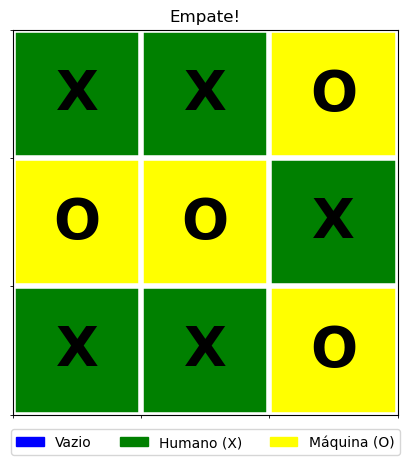

In [6]:
# roda uma partida completa, humano contra máquina
#   humano_comeca -> True: o humano (X) começa; False: a máquina (O) começa
def jogar(humano_comeca=True):
    tab = criar_tabuleiro()                           # estado inicial: tabuleiro vazio
    vez = HUMANO if humano_comeca else MAQUINA
    titulo = "Jogo da Velha - você é o X"
    exibir(tab, titulo)

    # turnos alternados até alguém ganhar ou empatar
    while not fim_de_jogo(tab):
        if vez == HUMANO:
            jogada = pedir_jogada_humano(tab)
            if jogada is None:                         # humano digitou q
                print("Partida encerrada.")
                return
            tab[jogada[0]][jogada[1]] = HUMANO
            titulo = "Você jogou na posição %d" % (jogada[0] * 3 + jogada[1] + 1)
        else:
            i, j = melhor_jogada(tab)                  # máquina decide com o minimax
            tab[i][j] = MAQUINA
            titulo = "Máquina jogou na posição %d (nós visitados: %d)" % (i * 3 + j + 1, nos_visitados)
        exibir(tab, titulo)
        vez = MAQUINA if vez == HUMANO else HUMANO     # passa a vez pro outro jogador

    # fim de jogo: mostra o resultado
    v = vencedor(tab)
    if v == HUMANO:
        exibir(tab, "Você venceu!")
    elif v == MAQUINA:
        exibir(tab, "A máquina venceu!")
    else:
        exibir(tab, "Empate!")


jogar(humano_comeca=True)

### Teste: a máquina é imbatível?

Simula algumas partidas com um humano que joga **aleatoriamente** (nas duas ordens de início). Como o Minimax é ótimo, a máquina nunca deve perder.

In [7]:
# simula uma partida inteira sem precisar digitar nada:
# o "humano" escolhe uma casa vazia aleatória e a máquina usa o minimax
# retorna quem ganhou (HUMANO, MAQUINA ou VAZIO para empate)
def partida_simulada(humano_comeca):
    tab = criar_tabuleiro()
    vez = HUMANO if humano_comeca else MAQUINA
    while not fim_de_jogo(tab):
        if vez == HUMANO:
            i, j = random.choice(jogadas_possiveis(tab))   # jogada aleatória
        else:
            i, j = melhor_jogada(tab)                      # jogada ótima
        tab[i][j] = vez
        vez = MAQUINA if vez == HUMANO else HUMANO
    return vencedor(tab)


# conta os resultados de várias partidas, metade com cada um começando
resultados = {'humano': 0, 'maquina': 0, 'empate': 0}
for comeca in (True, False):
    for _ in range(10):   # sem poda cada partida é lenta, por isso poucas
        v = partida_simulada(comeca)
        if v == HUMANO:
            resultados['humano'] += 1
        elif v == MAQUINA:
            resultados['maquina'] += 1
        else:
            resultados['empate'] += 1

print("20 partidas contra um humano aleatório:", resultados)

20 partidas contra um humano aleatório: {'humano': 0, 'maquina': 19, 'empate': 1}
